# Día 6 — Visualización multidimensional y optimización de modelos

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Dos temas que cierran la unidad de reducción de dimensionalidad:

1. **Visualización multidimensional.** Nuestros datos tienen 9, 17 o 37 columnas, pero una pantalla tiene 2 dimensiones. ¿Cómo «ver» datos de muchas dimensiones sin engañarnos?
2. **Optimización de modelos.** Hasta ahora elegimos hiperparámetros con un `for` y **una sola** Validation. Hoy aprendemos a hacerlo de forma más confiable y automática: **validación cruzada**, `GridSearchCV` y `RandomizedSearchCV`.

## Cómo está organizada cada parte

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | `head`, tipos y resumen |
| 2. Entender el problema | ¿Qué queremos ver u optimizar? |
| 3. Preparar | Lo mismo de días anteriores, con el antes y el después |
| 4. Línea base | Lo que obtenemos sin la técnica |
| 5. La técnica a mano | Con números pequeños |
| 6. Versión simple con scikit-learn | Pocas líneas comentadas |
| 7. Métricas a mano y con scikit-learn | Train frente a Validation (o frente a la validación cruzada) |
| 8. Hiperparámetros, uno por uno | Qué controla cada uno |
| 9. Probar combinaciones | Con `for` y con las búsquedas automáticas |
| 10. Resultado final | Qué elegimos, y Test una sola vez |

## Los datasets (los mismos de días anteriores)

| Parte | Dataset | Para qué |
|---|---|---|
| A | CC GENERAL con los 4 segmentos del Día 4 | Visualizar 9 dimensiones: matriz de dispersión, coordenadas paralelas, PCA y t-SNE |
| B | Credit Risk (Día 3) | Optimizar un Random Forest: validación cruzada, Grid Search y Random Search |
| C | CC GENERAL | Optimizar un clustering: elegir `k` con remuestreo y estabilidad |
| D | Credit Risk y BankChurners | **Comparación final**: tres modelos optimizados en cada dataset |

# 0. Librerías

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))   # evita un aviso en Windows y permite usar todos los núcleos
os.environ["OMP_NUM_THREADS"] = "1"                                  # evita un aviso de memoria de K-Means en Windows

from pathlib import Path
import time
import numpy as np                                 # cálculos numéricos
import pandas as pd                                # tablas
import matplotlib.pyplot as plt                    # gráficos
from pandas.plotting import scatter_matrix, parallel_coordinates   # gráficos de muchas variables

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     GridSearchCV, RandomizedSearchCV)          # validación cruzada y búsquedas
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness                              # t-SNE y su métrica de calidad
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, silhouette_score, adjusted_rand_score
from scipy.stats import randint                                                 # distribuciones para Random Search

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
for f in ["CC_GENERAL.csv", "credit_risk_dataset.csv", "BankChurners.csv"]:
    print("Encontrado" if (DATA_DIR / f).exists() else "FALTA", "→", (DATA_DIR / f).resolve())

Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\credit_risk_dataset.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\BankChurners.csv


# Parte A · Visualización multidimensional: los segmentos de tarjeta

**El problema.** En el Día 4 segmentamos 8 949 clientes con **9 variables**. Para mostrar el resultado a un gerente necesitamos un gráfico, pero un gráfico tiene 2 dimensiones (3 con mucho esfuerzo). Hoy comparamos cinco formas de mirar datos de muchas dimensiones y qué muestra y qué esconde cada una.

## A.1 Mirar los datos (preparados como en el Día 4)

In [2]:
cc = pd.read_csv(DATA_DIR / "CC_GENERAL.csv").dropna(subset=["CREDIT_LIMIT"])
VARS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
        "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
MONTOS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]

def preparar(df):
    # Igual que el Día 4: logaritmo de los 7 montos
    d = df[VARS].copy()
    d[MONTOS] = np.log1p(d[MONTOS])
    return d

escalador = StandardScaler().fit(preparar(cc))
X = escalador.transform(preparar(cc))                                     # 8 949 × 9, estandarizado
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)              # los 4 segmentos del Día 4
perfil = pd.DataFrame(X, columns=VARS).groupby(km.labels_).mean()
# Nombres con la regla del Día 4
pend = list(perfil.index); NOMBRES = {}
for var, nom in [("PRC_FULL_PAYMENT", "Totaleros"), ("CASH_ADVANCE", "Usuarios de avances"), ("PURCHASES", "Compradores que financian")]:
    s = perfil.loc[pend, var].idxmax(); NOMBRES[s] = nom; pend.remove(s)
NOMBRES[pend[0]] = "Poco activos"
COLORES = {"Totaleros": "seagreen", "Usuarios de avances": "darkorange", "Compradores que financian": "steelblue", "Poco activos": "crimson"}

datos = pd.DataFrame(X, columns=VARS)
datos["segmento"] = pd.Series(km.labels_).map(NOMBRES)
print(datos["segmento"].value_counts())
datos.head()

segmento
Compradores que financian    2770
Poco activos                 2444
Usuarios de avances          2438
Totaleros                    1297
Name: count, dtype: int64


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,segmento
0,-1.205498,-0.113732,-0.987198,0.394362,-0.930636,-0.806649,-1.447095,-0.825080,-0.525588,Poco activos
1,0.948821,-1.680213,-0.987198,-1.087586,1.528788,-1.221928,0.925997,1.065109,0.234159,Usuarios de avances
2,0.824885,0.600600,1.061910,-1.087586,-0.930636,1.269742,1.010161,-0.119646,-0.525588,Compradores que financian
3,0.624529,0.827395,1.265665,-1.087586,0.564410,-1.014290,1.010161,-4.163779,-0.525588,Poco activos
4,0.271106,-0.708741,-0.114417,-1.087586,-0.930636,-1.014290,-1.224854,-0.065306,-0.525588,Poco activos


Cada cliente es un punto en un espacio de **9 dimensiones** (una por columna). No podemos dibujarlo directamente. Hay dos caminos:

| Camino | Técnicas | Ventaja | Desventaja |
|---|---|---|---|
| **Mostrar varias vistas** de las variables originales | Matriz de dispersión, coordenadas paralelas, mapa de calor | Cada eje es una variable que entendemos | Muchas vistas parciales; nunca se ve todo junto |
| **Reducir a 2 dimensiones** | PCA, t-SNE | Un solo mapa con todos los clientes | Los ejes ya no son variables originales; algo se pierde |

## A.2 Línea base: dos variables a la vez

La forma más simple es un gráfico de dispersión de **dos** variables. Es la «línea base» de la visualización: lo que ve quien no usa ninguna técnica.

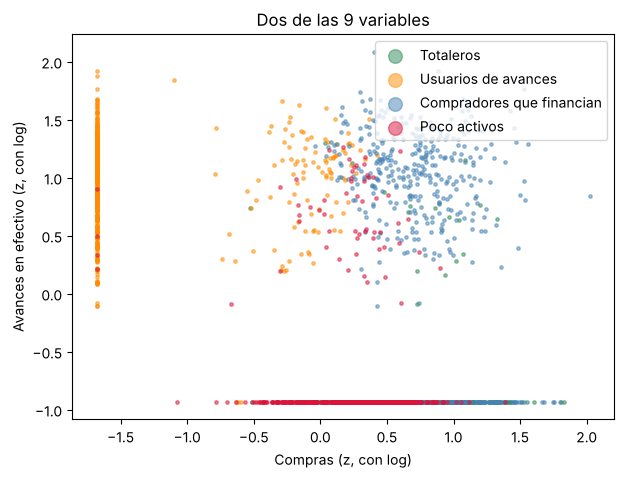

In [3]:
muestra = datos.sample(2000, random_state=1)                 # 2 000 clientes para que el gráfico no se sature
fig, ax = plt.subplots(figsize=(7, 5))
for nom, color in COLORES.items():
    m = muestra["segmento"] == nom
    ax.scatter(muestra.loc[m, "PURCHASES"], muestra.loc[m, "CASH_ADVANCE"], s=6, alpha=0.5, color=color, label=nom)
ax.set(xlabel="Compras (z, con log)", ylabel="Avances en efectivo (z, con log)", title="Dos de las 9 variables"); ax.legend(markerscale=4)
plt.show()

Se separan bien los **usuarios de avances** (arriba a la izquierda), pero los totaleros, los compradores que financian y los poco activos se superponen: lo que los distingue está en **otras** variables (porcentaje de pago total, saldo). Dos variables no bastan.

## A.3 Matriz de dispersión: todas las parejas

Dibuja un gráfico de dispersión para **cada pareja** de variables y, en la diagonal, el histograma de cada una. Con 9 variables son 81 gráficos; usamos 5 para que se lea.

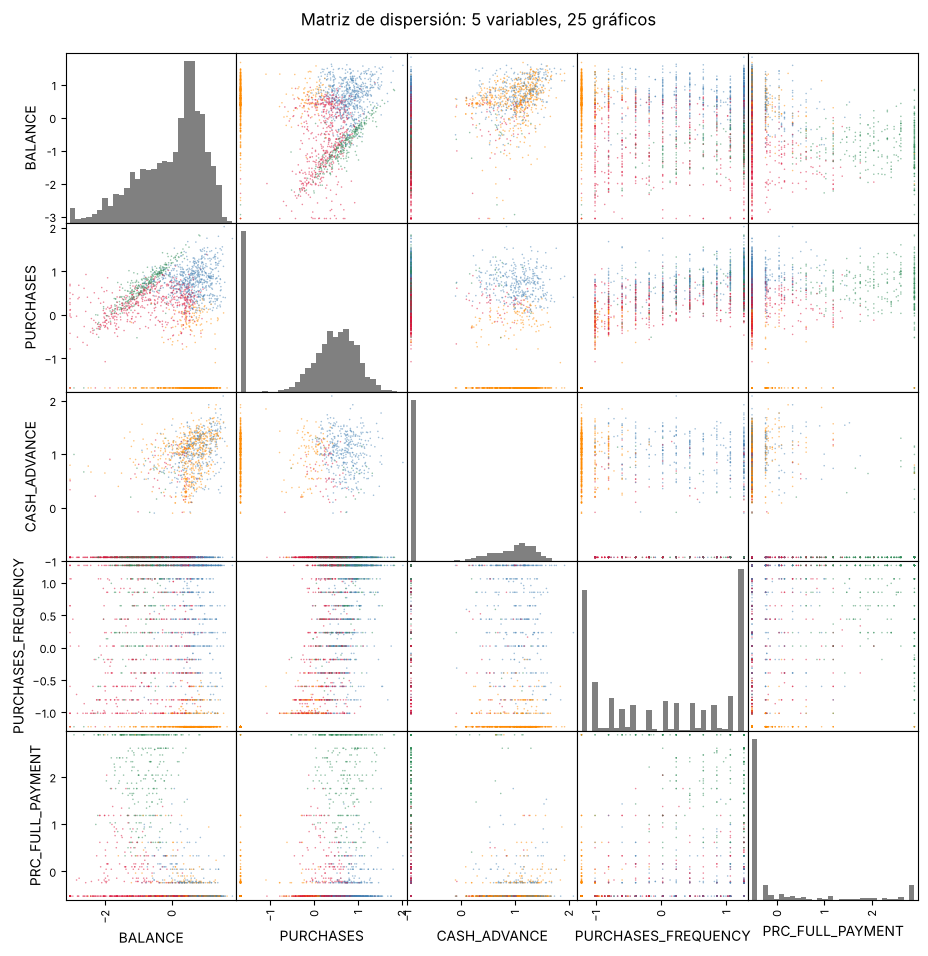

In [4]:
cinco = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
colores_puntos = muestra["segmento"].map(COLORES)
scatter_matrix(muestra[cinco], c=colores_puntos, figsize=(11, 11), s=5, alpha=0.5, diagonal="hist", hist_kwds={"bins": 30, "color": "gray"})
plt.suptitle("Matriz de dispersión: 5 variables, 25 gráficos", y=0.92); plt.show()

**Lee la matriz.** Busca en qué gráficos se separan los colores. El verde (totaleros) se separa en las columnas de `PRC_FULL_PAYMENT`; el naranja (avances) en las de `CASH_ADVANCE`; el azul y el rojo se separan por `PURCHASES_FREQUENCY` y `BALANCE`. Ningún gráfico solo muestra los 4 grupos; hay que juntar varias vistas en la cabeza.

## A.4 Coordenadas paralelas: un cliente = una línea

Cada variable es un **eje vertical** y cada cliente es una **línea** que pasa por sus valores en todos los ejes. Clientes parecidos dibujan líneas parecidas.

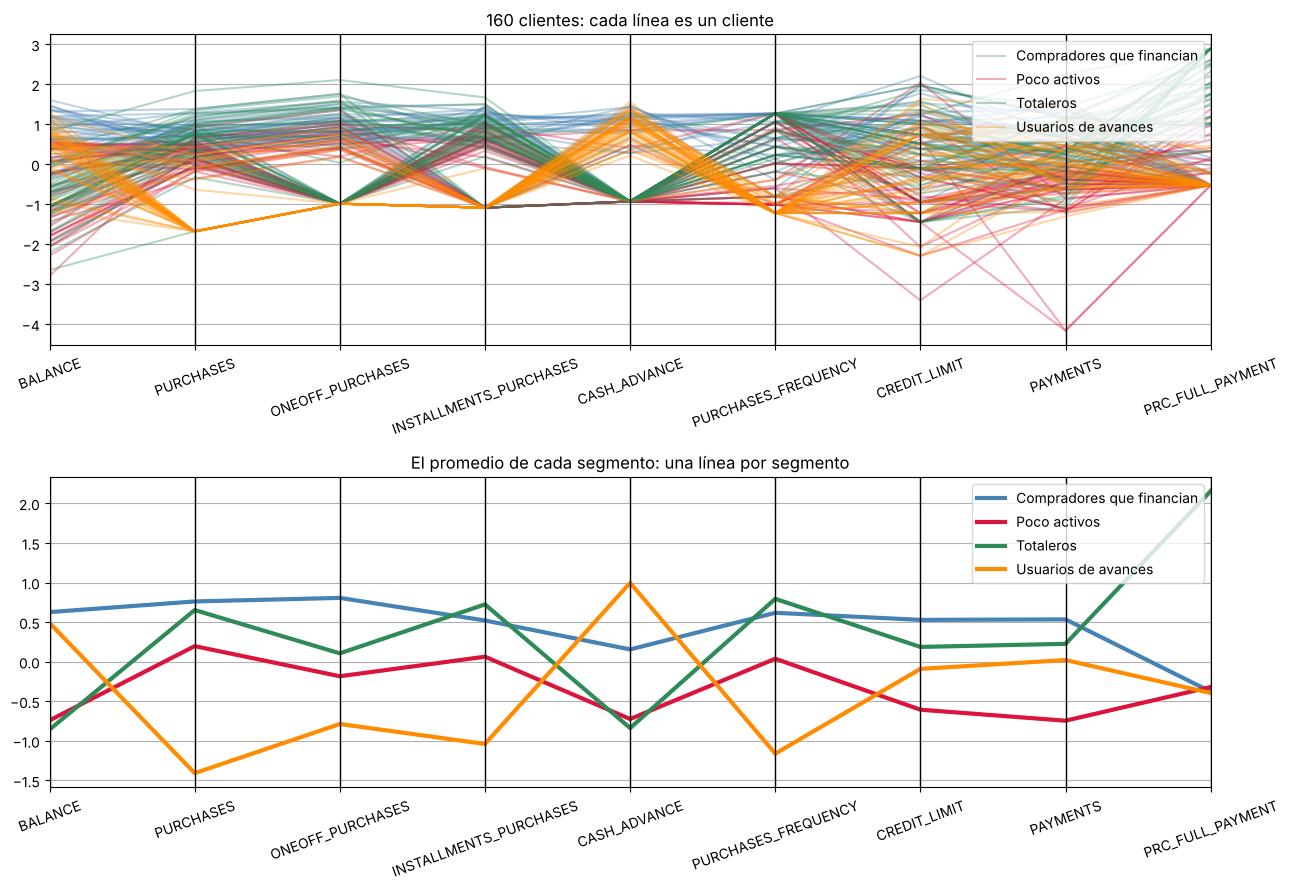

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(13, 9))
pocos = muestra.groupby("segmento").sample(40, random_state=0).sort_values("segmento")   # ordenado: los colores coinciden con la leyenda   # 40 clientes por segmento
parallel_coordinates(pocos[VARS + ["segmento"]], "segmento", color=[COLORES[s] for s in sorted(COLORES)], alpha=0.35, ax=ax[0])
ax[0].set_title("160 clientes: cada línea es un cliente"); ax[0].tick_params(axis="x", rotation=20)
medias = datos.groupby("segmento")[VARS].mean().reset_index()
parallel_coordinates(medias, "segmento", color=[COLORES[s] for s in medias["segmento"]], linewidth=3, ax=ax[1])
ax[1].set_title("El promedio de cada segmento: una línea por segmento"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Lee las coordenadas paralelas.** Arriba hay demasiadas líneas para seguirlas una por una, pero se ven «haces» de colores. Abajo, con el promedio de cada segmento, el perfil es clarísimo: la línea naranja (avances) sube en `CASH_ADVANCE` y baja en compras; la verde (totaleros) se dispara en `PRC_FULL_PAYMENT`; la roja (poco activos) queda baja en casi todo. Es el mismo contenido que el mapa de calor del Día 4, dibujado como líneas.

## A.5 Reducir a 2 dimensiones con PCA (Día 5)

PCA busca las direcciones de máxima varianza. Con 2 componentes, cada cliente queda con 2 coordenadas y se dibuja en un plano. También probamos 3 componentes en 3D.

Varianza explicada: [0.371 0.236 0.112] | con 2: 0.607 | con 3: 0.719


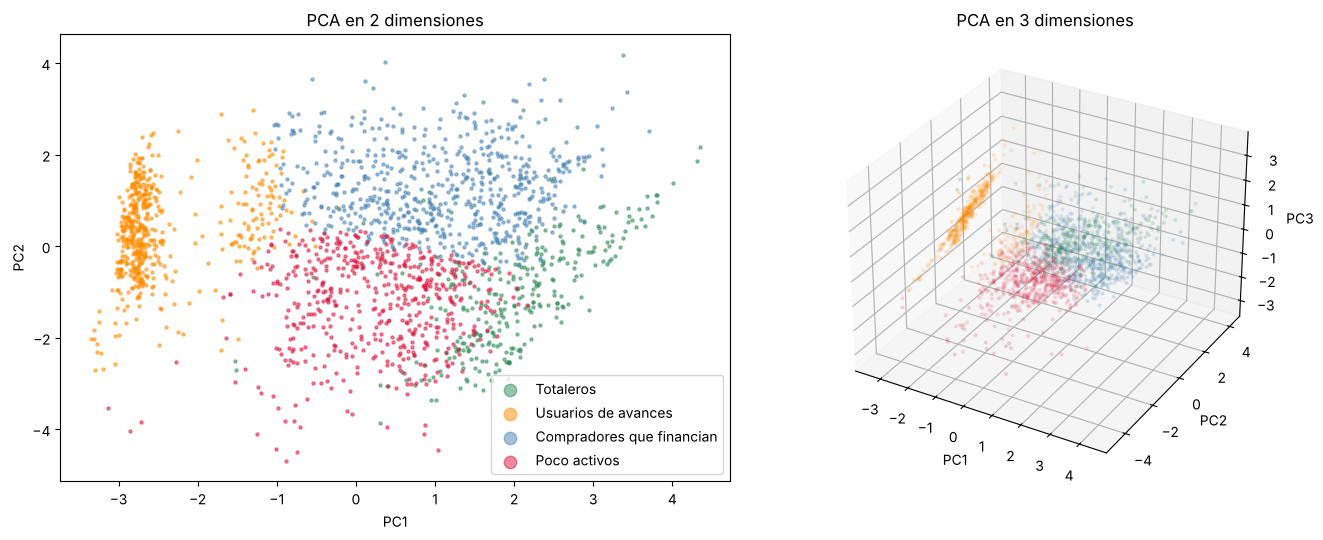

In [6]:
pca = PCA(n_components=3).fit(X)
Z = pca.transform(muestra[VARS].values)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3), "| con 2:", round(pca.explained_variance_ratio_[:2].sum(), 3), "| con 3:", round(pca.explained_variance_ratio_.sum(), 3))
fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
for nom, color in COLORES.items():
    m = (muestra["segmento"] == nom).values
    ax1.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=color, label=nom)
    ax2.scatter(Z[m, 0], Z[m, 1], Z[m, 2], s=4, alpha=0.4, color=color)
ax1.set(xlabel="PC1", ylabel="PC2", title="PCA en 2 dimensiones"); ax1.legend(markerscale=4)
ax2.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="PCA en 3 dimensiones")
plt.tight_layout(); plt.show()

Con 2 componentes vemos el 61 % de la información y los 4 segmentos ocupan zonas distintas, aunque con bordes que se tocan. El 3D agrega un 11 % más, pero en una pantalla plana cuesta leerlo: en la práctica se usa poco.

## A.6 t-SNE a mano: conservar a los vecinos

PCA conserva la **varianza** (las distancias grandes). **t-SNE** (*t-distributed Stochastic Neighbor Embedding*) persigue otra cosa: que los clientes que son **vecinos** en 9 dimensiones sigan siendo vecinos en el plano. La idea, en tres pasos:

1. **En 9 dimensiones**, para cada cliente calcula qué tan probable es que otro sea su vecino: alta si está cerca, casi cero si está lejos. La `perplexity` fija aproximadamente **cuántos vecinos** considera cada cliente.
2. **En 2 dimensiones**, coloca a los clientes al azar (o empezando desde PCA) y calcula las mismas probabilidades.
3. **Mueve los puntos** del plano, poco a poco, hasta que las probabilidades del plano se parezcan a las de 9 dimensiones.

Ejemplo con 4 clientes en una recta (1 dimensión, para seguirlo a mano):

In [7]:
pos = np.array([0.0, 1.0, 1.5, 6.0])                     # 4 clientes: A, B y C juntos, D lejos
nombres = ["A", "B", "C", "D"]
d2 = (pos[:, None] - pos[None, :]) ** 2                  # distancias al cuadrado
sigma = 1.0                                               # «radio» de vecindad (lo controla la perplexity)
p = np.exp(-d2 / (2 * sigma ** 2)); np.fill_diagonal(p, 0)
p = p / p.sum(axis=1, keepdims=True)                      # probabilidad de que j sea vecino de i (cada fila suma 1)
print("Probabilidad de ser vecino (fila = cliente, columna = posible vecino):")
print(pd.DataFrame(p.round(3), index=nombres, columns=nombres))

Probabilidad de ser vecino (fila = cliente, columna = posible vecino):
       A      B      C    D
A  0.000  0.651  0.349  0.0
B  0.407  0.000  0.593  0.0
C  0.269  0.731  0.000  0.0
D  0.000  0.085  0.915  0.0


**Lee la tabla.** Para A, sus vecinos probables son B (0,65) y C (0,35); D tiene probabilidad 0. Para D, todos están lejos, pero C es el «menos lejano» (0,92). t-SNE coloca los puntos en el plano para que estas probabilidades se mantengan: **A, B y C juntos y D aparte**. No le importa si D está a 6 o a 60 de distancia: solo le importa quién es vecino de quién.

## A.7 La versión simple con scikit-learn

t-SNE en 9.4 s; cada cliente tiene ahora 2 coordenadas:
   tsne_1     tsne_2
0   12.86  40.730000
1   17.84  43.950001
2  -11.11  44.160000


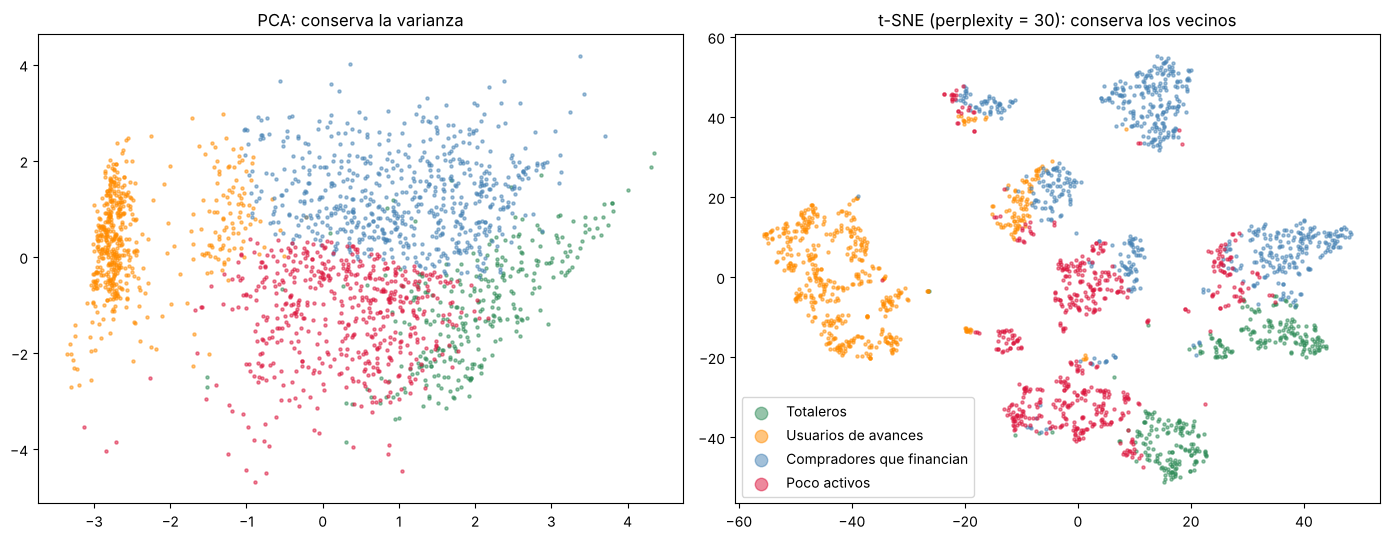

In [8]:
Xm = muestra[VARS].values                                   # 2 000 clientes (t-SNE es lento con muchos)
inicio = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)   # 1) crear
E = tsne.fit_transform(Xm)                                                  # 2) y 3) ajustar y obtener coordenadas
print(f"t-SNE en {time.time() - inicio:.1f} s; cada cliente tiene ahora 2 coordenadas:")
print(pd.DataFrame(E[:3], columns=["tsne_1", "tsne_2"]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for nom, color in COLORES.items():
    m = (muestra["segmento"] == nom).values
    ax[0].scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=color, label=nom)
    ax[1].scatter(E[m, 0], E[m, 1], s=5, alpha=0.5, color=color, label=nom)
ax[0].set_title("PCA: conserva la varianza"); ax[1].set_title("t-SNE (perplexity = 30): conserva los vecinos")
ax[1].legend(markerscale=4); plt.tight_layout(); plt.show()

**Compara.** En t-SNE los segmentos aparecen como «islas» más compactas y mejor separadas. Pero **cuidado**:

- En t-SNE el **tamaño** de una isla y la **distancia entre islas** no significan nada. Solo importa quién está junto a quién.
- Los ejes de t-SNE no tienen interpretación (en PCA sí: las cargas).
- t-SNE **no tiene `transform`**: no puede ubicar a un cliente nuevo sin rehacer todo el mapa.

## A.8 Métricas: ¿qué tan fiel es cada mapa?

**Confiabilidad** (*trustworthiness*): de los 10 vecinos más cercanos de cada cliente **en el mapa**, ¿cuántos eran también vecinos cercanos en las 9 dimensiones? Vale 1 si el mapa nunca junta a clientes que en realidad estaban lejos.

Primero a mano, para un cliente: contamos cuántos de sus 10 vecinos en el mapa también están entre sus 10 vecinos reales.

In [9]:
def vecinos(M, i, k=10):
    d = ((M - M[i]) ** 2).sum(axis=1)
    return set(np.argsort(d)[1:k + 1])                    # los k más cercanos (sin contarse a sí mismo)

i = 0
reales = vecinos(Xm, i)
for nombre, mapa in [("PCA", Z[:, :2]), ("t-SNE", E)]:
    comunes = len(reales & vecinos(mapa, i))
    print(f"Cliente 0, {nombre:5s}: {comunes} de sus 10 vecinos en el mapa también son vecinos en 9 dimensiones")

print("\nConfiabilidad promedio (scikit-learn, 10 vecinos):")
print("  PCA  :", round(trustworthiness(Xm, Z[:, :2], n_neighbors=10), 3))
print("  t-SNE:", round(trustworthiness(Xm, E, n_neighbors=10), 3))

Cliente 0, PCA  : 1 de sus 10 vecinos en el mapa también son vecinos en 9 dimensiones
Cliente 0, t-SNE: 6 de sus 10 vecinos en el mapa también son vecinos en 9 dimensiones

Confiabilidad promedio (scikit-learn, 10 vecinos):
  PCA  : 0.894


  t-SNE: 0.995


Para el cliente 0, solo 1 de sus 10 vecinos en el mapa de PCA era vecino real; en t-SNE, 6 de 10. En promedio, t-SNE (0,995) conserva mejor los vecindarios que PCA (0,894): casi todo lo que aparece junto en su mapa está realmente junto. PCA tiene menor confiabilidad local, pero conserva mejor la **forma global** (qué está lejos de qué) y sus ejes se interpretan.

## A.9 Los hiperparámetros de t-SNE y un `for`

| Hiperparámetro | Qué controla | Por defecto |
|---|---|---|
| `n_components` | Dimensiones del mapa (2 o 3) | 2 |
| `perplexity` | Cuántos vecinos considera cada punto (entre 5 y 50 es lo usual; debe ser menor que el número de filas) | 30 |
| `learning_rate` | Qué tan grandes son los movimientos al acomodar los puntos | `"auto"` |
| `max_iter` | Cuántas vueltas de acomodo | 1000 |
| `init` | Posición inicial: `"random"` o `"pca"` (más estable) | `"pca"` |
| `random_state` | Semilla: t-SNE cambia mucho con ella | `None` |

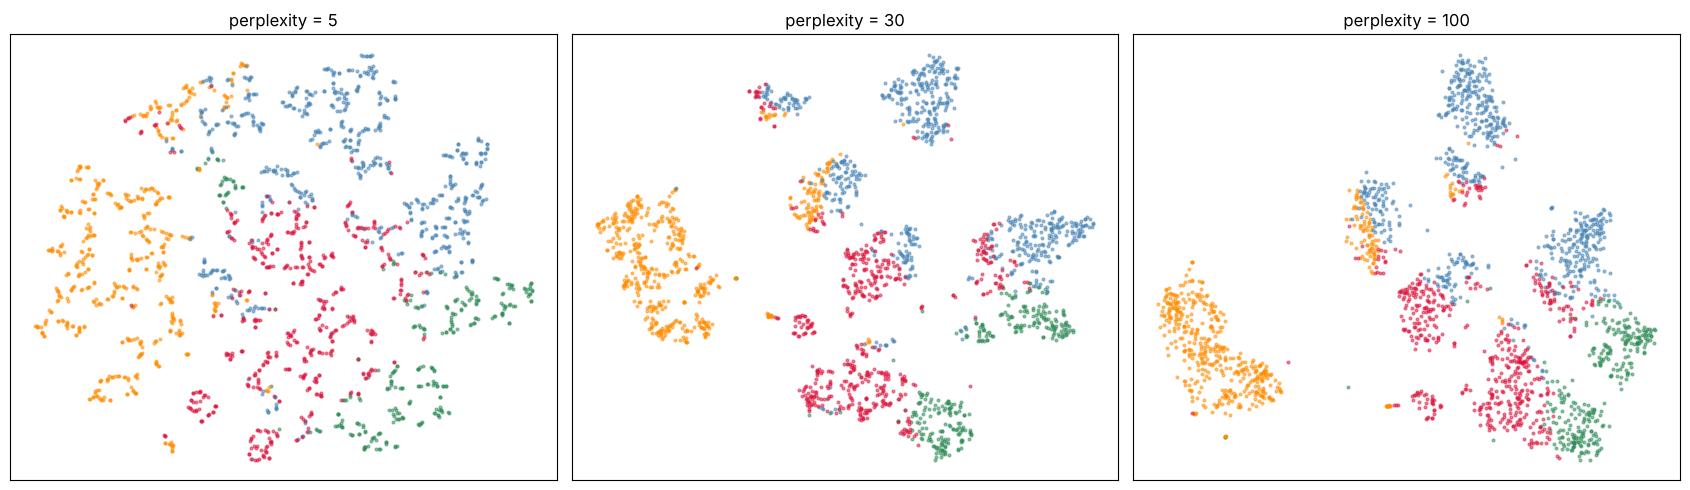

,perplexity,confiabilidad,segundos
0,5,0.994,8.099
1,30,0.995,9.800
2,100,0.994,15.910


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
filas = []
for a_, perp in zip(ax, [5, 30, 100]):
    inicio = time.time()
    Ep = TSNE(n_components=2, perplexity=perp, init="pca", random_state=42).fit_transform(Xm)
    filas.append({"perplexity": perp, "confiabilidad": trustworthiness(Xm, Ep, n_neighbors=10), "segundos": time.time() - inicio})
    for nom, color in COLORES.items():
        m = (muestra["segmento"] == nom).values
        a_.scatter(Ep[m, 0], Ep[m, 1], s=4, alpha=0.5, color=color)
    a_.set_title(f"perplexity = {perp}"); a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()
pd.DataFrame(filas).round(3)

**Interpretación.** Con `perplexity = 5` cada cliente mira muy pocos vecinos y el mapa se rompe en muchas islitas que no son segmentos reales. Con 30 aparecen islas bien definidas, aunque un mismo segmento puede quedar partido en varias (los compradores que financian aparecen en tres islas). Con 100 las islas se juntan y el mapa es más global. La confiabilidad casi no cambia: las tres versiones son fieles en lo local, pero **cuentan historias distintas a simple vista**. Por eso nunca se saca una conclusión de un solo t-SNE.

## A.10 Resultado final de la Parte A

| Técnica | Qué muestra bien | Qué esconde | Úsala para… |
|---|---|---|---|
| Dispersión de 2 variables | La relación entre esas dos | Las otras 7 | Una pregunta concreta |
| Matriz de dispersión | Todas las parejas | Combinaciones de 3 o más; se satura con muchas variables | Explorar al inicio |
| Coordenadas paralelas | El perfil completo de cada grupo | Se satura con muchos clientes | Comparar perfiles de segmentos |
| PCA 2D | La forma global; ejes interpretables | ≈ 39 % de la información; vecindades | Mapas para informes; ubicar clientes nuevos |
| t-SNE | Quién es vecino de quién; islas | Distancias entre islas y tamaños; no ubica clientes nuevos | Explorar si hay grupos |

**Para un informe:** coordenadas paralelas de los promedios (o el mapa de calor) para **explicar** los segmentos, y PCA 2D para **ubicar** a los clientes. t-SNE, solo como exploración y con varias `perplexity`.

# Parte B · Optimizar un Random Forest con Credit Risk

**El problema.** Predecir qué préstamos caerán en impago (22 %). En el Día 3 elegimos hiperparámetros con un `for` y **una sola** Validation. Hoy veremos por qué eso puede engañar y cómo hacerlo mejor.

## B.1 Mirar y preparar los datos (como en el Día 3)

In [11]:
cr = pd.read_csv(DATA_DIR / "credit_risk_dataset.csv")
print("Filas y columnas:", cr.shape)
cr.head()

Filas y columnas: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [12]:
cr = cr[(cr["person_age"] <= 100) & ~(cr["person_emp_length"] > 60)].drop_duplicates().reset_index(drop=True)   # errores y duplicados
y_cr = cr.pop("loan_status")                                     # 1 = impago
CAT = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
NUM = [c for c in cr.columns if c not in CAT]
print("Préstamos:", len(cr), "| impago:", round(y_cr.mean(), 3))

# Test (15 %) se aparta y no se toca hasta el final. El resto es para entrenar y validar.
X_dev, X_test, y_dev, y_test = train_test_split(cr, y_cr, test_size=0.15, random_state=42, stratify=y_cr)
# Para que las búsquedas tarden poco usamos 8 000 préstamos del resto (estratificado)
X_tr, _, y_tr, _ = train_test_split(X_dev, y_dev, train_size=8000, random_state=42, stratify=y_dev)
print("Para entrenar y validar:", len(X_tr), "| Test:", len(X_test))

preparar_cr = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),                                   # rellenar la tasa y la antigüedad faltantes
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])                            # One-Hot de las 4 categorías

Préstamos: 32409 | impago: 0.219
Para entrenar y validar: 8000 | Test: 4862


**¿Dónde quedó Validation?** Hoy no separamos una Validation fija: la **validación cruzada** la va a construir varias veces dentro de esos 8 000 préstamos. Test sigue aparte.

## B.2 Parámetros, hiperparámetros y línea base

| | Parámetros | Hiperparámetros |
|---|---|---|
| ¿Quién los fija? | El modelo, al entrenar (`fit`) | Nosotros, antes de entrenar |
| Ejemplos | Las preguntas y umbrales de cada árbol; los centros de K-Means | `max_depth`, `n_estimators`, `n_neighbors`, `k` |
| ¿Cómo se eligen? | Minimizando el error en Train | **Optimizando** el resultado en datos no vistos |

**Optimizar un modelo** = encontrar los hiperparámetros con mejor resultado en datos que el modelo no vio, sin tocar Test.

In [13]:
rf_defecto = Pipeline([("preparar", preparar_cr), ("rf", RandomForestClassifier(random_state=42, n_jobs=-1))])
base = Pipeline([("preparar", preparar_cr), ("dummy", DummyClassifier(strategy="most_frequent"))])
print("Modelos a mejorar: la línea base (siempre «paga») y un Random Forest con todos sus valores por defecto.")

Modelos a mejorar: la línea base (siempre «paga») y un Random Forest con todos sus valores por defecto.


## B.3 El problema de una sola Validation

Medimos el **mismo** Random Forest con 5 divisiones Train/Validation distintas (75/25). Si una sola Validation fuera confiable, el F1 debería salir casi igual siempre.

In [14]:
filas = []
for semilla in range(5):
    a, b, c, d = train_test_split(X_tr, y_tr, test_size=0.25, random_state=semilla, stratify=y_tr)   # otra división
    rf_defecto.fit(a, c)
    filas.append({"división (semilla)": semilla, "F1 Validation": f1_score(d, rf_defecto.predict(b))})
una_val = pd.DataFrame(filas)
print(una_val.round(3).to_string(index=False))
print(f"\nMismo modelo, cinco Validation: de {una_val['F1 Validation'].min():.3f} a {una_val['F1 Validation'].max():.3f}")

 división (semilla)  F1 Validation
                  0          0.820
                  1          0.793
                  2          0.834
                  3          0.808
                  4          0.810

Mismo modelo, cinco Validation: de 0.793 a 0.834


**El mismo modelo** sale con F1 distintos según qué préstamos cayeron en Validation, con una diferencia de unos 4 puntos entre la mejor y la peor división. Si comparamos dos configuraciones con una sola división, una puede «ganar» solo por suerte. Necesitamos medir **varias veces** y promediar.

## B.4 Validación cruzada a mano

**Validación cruzada con k pliegues (k-fold):**

1. Dividir los datos en `k` partes iguales (pliegues).
2. Entrenar con `k − 1` partes y validar con la que queda.
3. Repetir `k` veces, cambiando el pliegue de validación, hasta que **cada fila** haya servido una vez para validar.
4. Reportar el **promedio** (resultado esperado) y la **desviación** (qué tan estable es).

Ejemplo con 10 filas y 5 pliegues:

In [15]:
diez = np.arange(10)
for i, (idx_entrenar, idx_validar) in enumerate(KFold(n_splits=5).split(diez), start=1):
    print(f"Vuelta {i}: entrena con filas {idx_entrenar.tolist()} · valida con {idx_validar.tolist()}")

Vuelta 1: entrena con filas [2, 3, 4, 5, 6, 7, 8, 9] · valida con [0, 1]
Vuelta 2: entrena con filas [0, 1, 4, 5, 6, 7, 8, 9] · valida con [2, 3]
Vuelta 3: entrena con filas [0, 1, 2, 3, 6, 7, 8, 9] · valida con [4, 5]
Vuelta 4: entrena con filas [0, 1, 2, 3, 4, 5, 8, 9] · valida con [6, 7]
Vuelta 5: entrena con filas [0, 1, 2, 3, 4, 5, 6, 7] · valida con [8, 9]


Cada fila aparece **exactamente una vez** en validación. Ahora con los préstamos: hacemos el bucle a mano. Usamos `StratifiedKFold`, que además mantiene el 22 % de impagos en cada pliegue.

In [16]:
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1s = []
for i, (ie, iv) in enumerate(pliegues.split(X_tr, y_tr), start=1):
    rf_defecto.fit(X_tr.iloc[ie], y_tr.iloc[ie])                         # entrenar con 4 pliegues
    f1 = f1_score(y_tr.iloc[iv], rf_defecto.predict(X_tr.iloc[iv]))      # validar con el quinto
    f1s.append(f1)
    print(f"Pliegue {i}: entrena {len(ie)} · valida {len(iv)} · impago en validación {y_tr.iloc[iv].mean():.3f} · F1 = {f1:.3f}")
print(f"\nPromedio = ({' + '.join(f'{v:.3f}' for v in f1s)}) / 5 = {np.mean(f1s):.3f} · desviación = {np.std(f1s):.3f}")

Pliegue 1: entrena 6400 · valida 1600 · impago en validación 0.219 · F1 = 0.817


Pliegue 2: entrena 6400 · valida 1600 · impago en validación 0.219 · F1 = 0.792


Pliegue 3: entrena 6400 · valida 1600 · impago en validación 0.219 · F1 = 0.788


Pliegue 4: entrena 6400 · valida 1600 · impago en validación 0.219 · F1 = 0.812


Pliegue 5: entrena 6400 · valida 1600 · impago en validación 0.219 · F1 = 0.803

Promedio = (0.817 + 0.792 + 0.788 + 0.812 + 0.803) / 5 = 0.802 · desviación = 0.011


## B.5 La versión simple con scikit-learn

`cross_val_score` hace el mismo bucle en una línea. `cross_validate` además devuelve el resultado en Train de cada pliegue, para revisar la **brecha**.

In [17]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes = cross_val_score(rf_defecto, X_tr, y_tr, cv=cv5, scoring="f1")                 # F1 de cada pliegue
print("cross_val_score:", puntajes.round(3), "→ promedio", round(puntajes.mean(), 3))

res = cross_validate(rf_defecto, X_tr, y_tr, cv=cv5, scoring="f1", return_train_score=True)
print(f"\nRandom Forest por defecto → F1 Train {res['train_score'].mean():.3f} | F1 validación cruzada {res['test_score'].mean():.3f} ± {res['test_score'].std():.3f}")
res_b = cross_validate(base, X_tr, y_tr, cv=cv5, scoring="f1", return_train_score=True)
print(f"Línea base             → F1 Train {res_b['train_score'].mean():.3f} | F1 validación cruzada {res_b['test_score'].mean():.3f}")

cross_val_score: [0.817 0.792 0.788 0.812 0.803] → promedio 0.802



Random Forest por defecto → F1 Train 1.000 | F1 validación cruzada 0.802 ± 0.011


Línea base             → F1 Train 0.000 | F1 validación cruzada 0.000


**Lee la salida.** El mismo número que el bucle a mano. El Random Forest por defecto tiene F1 ≈ 1 en Train y ≈ 0,80 en validación cruzada: **memoriza** (árboles sin límite de profundidad). ¿Podemos encontrar hiperparámetros con mejor resultado o al menos con menos memorización?

## B.6 Los hiperparámetros de la búsqueda, uno por uno

| Herramienta | Hiperparámetro | Qué controla |
|---|---|---|
| `KFold` / `StratifiedKFold` | `n_splits` | Cuántos pliegues (5 o 10 es lo usual; más = más confiable y más lento) |
| | `shuffle`, `random_state` | Barajar las filas antes de dividir (con semilla fija) |
| `GridSearchCV` | `estimator` | El modelo o Pipeline a optimizar |
| | `param_grid` | Diccionario con los valores a probar de cada hiperparámetro; prueba **todas** las combinaciones |
| | `scoring` | La métrica a maximizar (`"f1"`, `"accuracy"`, `"neg_mean_absolute_error"`…) |
| | `cv` | La validación cruzada (un número o un objeto `StratifiedKFold`) |
| | `refit` | Si es `True`, al final reentrena el mejor modelo con todos los datos de entrenamiento |
| | `return_train_score` | Guardar también el resultado en Train (para ver la brecha) |
| | `n_jobs` | Cuántos núcleos del procesador usar (`-1` = todos) |
| `RandomizedSearchCV` | `param_distributions` | Valores o distribuciones de donde **sortear** combinaciones |
| | `n_iter` | Cuántas combinaciones sortear |

**Con un Pipeline**, el nombre de cada hiperparámetro lleva el nombre del paso y dos guiones bajos: `rf__max_depth` es el `max_depth` del paso `"rf"`.

## B.7 `GridSearchCV`: probar todas las combinaciones

In [18]:
rejilla = {"rf__max_depth": [4, 8, 12, None],          # profundidad máxima de cada árbol
           "rf__min_samples_leaf": [1, 5, 20],          # mínimo de préstamos en cada hoja
           "rf__class_weight": [None, "balanced"]}      # dar más peso a los impagos
modelo = Pipeline([("preparar", preparar_cr), ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))])
n_comb = 4 * 3 * 2
print(f"{n_comb} combinaciones × 5 pliegues = {n_comb * 5} entrenamientos")

inicio = time.time()
grid = GridSearchCV(modelo, rejilla, scoring="f1", cv=cv5, return_train_score=True, refit=True, n_jobs=-1)
grid.fit(X_tr, y_tr)
t_grid = time.time() - inicio
print(f"Listo en {t_grid:.0f} s")
print("Mejor combinación:", grid.best_params_)
print("Mejor F1 en validación cruzada:", round(grid.best_score_, 3))

24 combinaciones × 5 pliegues = 120 entrenamientos


Listo en 51 s
Mejor combinación: {'rf__class_weight': None, 'rf__max_depth': None, 'rf__min_samples_leaf': 1}
Mejor F1 en validación cruzada: 0.802


### Cómo estudiar `cv_results_`

`grid.cv_results_` guarda, para cada combinación, el promedio y la desviación del F1 en validación y en Train. Lo convertimos en tabla:

In [19]:
resultados = pd.DataFrame(grid.cv_results_)
tabla = resultados[["param_rf__max_depth", "param_rf__min_samples_leaf", "param_rf__class_weight",
                    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
tabla.columns = ["max_depth", "min_samples_leaf", "class_weight", "F1_train", "F1_cv", "desv_cv", "puesto"]
tabla["brecha"] = tabla["F1_train"] - tabla["F1_cv"]
tabla["max_depth"] = tabla["max_depth"].apply(lambda v: "None" if pd.isna(v) else str(int(v)))   # None → "None", para ordenar y dibujar
tabla["class_weight"] = tabla["class_weight"].fillna("None").astype(str)   # scikit-learn guarda None como vacío (NaN)
tabla.sort_values("puesto").head(8).round(3)

,max_depth,min_samples_leaf,class_weight,F1_train,F1_cv,desv_cv,puesto,brecha
9,None,1,None,1.000,0.802,0.011,1,0.198
6,12,1,None,0.864,0.799,0.014,2,0.065
7,12,5,None,0.831,0.794,0.015,3,0.036
3,8,1,None,0.828,0.791,0.015,4,0.037
10,None,5,None,0.835,0.790,0.012,5,0.045
21,None,1,balanced,0.999,0.789,0.018,6,0.210
4,8,5,None,0.817,0.788,0.012,7,0.029
8,12,20,None,0.798,0.779,0.014,8,0.019


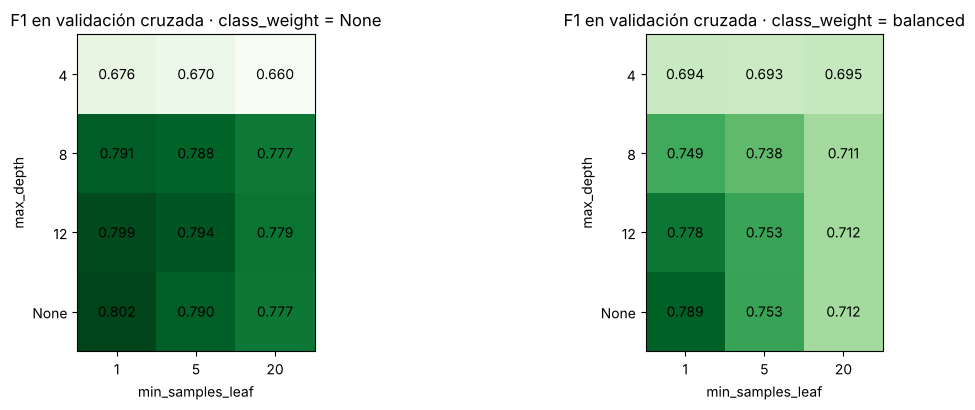

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for i, peso in enumerate([None, "balanced"]):
    t = tabla[tabla["class_weight"] == str(peso)]
    mapa = t.pivot(index="max_depth", columns="min_samples_leaf", values="F1_cv").reindex(["4", "8", "12", "None"])
    im = ax[i].imshow(mapa.values, cmap="Greens", vmin=tabla["F1_cv"].min(), vmax=tabla["F1_cv"].max())
    ax[i].set_xticks(range(3)); ax[i].set_xticklabels(mapa.columns); ax[i].set_yticks(range(4)); ax[i].set_yticklabels(mapa.index)
    for r in range(4):
        for c in range(3): ax[i].text(c, r, f"{mapa.values[r, c]:.3f}", ha="center", va="center")
    ax[i].set(xlabel="min_samples_leaf", ylabel="max_depth", title=f"F1 en validación cruzada · class_weight = {peso}"); ax[i].grid(False)
plt.tight_layout(); plt.show()

**Lee la tabla y los mapas.**

- **Profundidad:** con árboles poco profundos (4) el F1 es mucho menor: el modelo es demasiado simple. Desde 12 los resultados se parecen.
- **`class_weight="balanced"`** sube el recall (detecta más impagos) a costa de más falsas alarmas; aquí su F1 es **menor** en todas las combinaciones (mapa de la derecha), sobre todo con hojas grandes.
- **Brecha:** la ganadora (sin límite de profundidad y hojas de 1 préstamo, que son justo los valores por defecto) memoriza: F1 Train = 1 y brecha ≈ 0,20. La segunda (profundidad 12) tiene casi el mismo F1 en validación cruzada (0,799 frente a 0,802) con brecha 0,07; la tercera (profundidad 12, hojas de 5), 0,794 con brecha 0,04. Con una diferencia menor que la desviación entre pliegues (≈ 0,01), la de menor brecha es **más confiable**.
- **`desv_cv`** dice cuánto varía entre pliegues. Si dos combinaciones difieren menos que esa desviación, en la práctica **están empatadas**.

## B.8 `RandomizedSearchCV`: sortear combinaciones

Con muchos hiperparámetros, la rejilla explota: 5 hiperparámetros con 5 valores cada uno son 3 125 combinaciones. Random Search **sortea** `n_iter` combinaciones de unas distribuciones. Suele encontrar algo casi igual de bueno en mucho menos tiempo.

In [21]:
distribuciones = {"rf__max_depth": [4, 6, 8, 10, 12, 16, None],
                  "rf__min_samples_leaf": randint(1, 30),             # cualquier entero entre 1 y 29
                  "rf__max_features": ["sqrt", 0.3, 0.5, 0.8],        # cuántas columnas mira cada pregunta
                  "rf__n_estimators": randint(50, 300),               # cuántos árboles
                  "rf__class_weight": [None, "balanced"]}
inicio = time.time()
azar = RandomizedSearchCV(modelo, distribuciones, n_iter=15, scoring="f1", cv=cv5, return_train_score=True, random_state=42, n_jobs=-1)
azar.fit(X_tr, y_tr)
t_azar = time.time() - inicio
print(f"Random Search: 15 combinaciones en {t_azar:.0f} s → mejor F1 {azar.best_score_:.3f}")
print("Mejor combinación:", azar.best_params_)
print(f"Grid Search:   {n_comb} combinaciones en {t_grid:.0f} s → mejor F1 {grid.best_score_:.3f}")

Random Search: 15 combinaciones en 63 s → mejor F1 0.790
Mejor combinación: {'rf__class_weight': None, 'rf__max_depth': None, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 11, 'rf__n_estimators': 137}
Grid Search:   24 combinaciones en 51 s → mejor F1 0.802


**Interpretación.** Random Search exploró **más hiperparámetros** (5 en lugar de 3) con menos combinaciones y quedó cerca (0,790 frente a 0,802, poco más que la desviación entre pliegues). Aquí tardó algo más porque sorteó bosques de hasta 300 árboles; con rejillas grandes la ventaja de tiempo es enorme. Regla práctica: **Grid Search** con pocos hiperparámetros y pocos valores; **Random Search** cuando hay muchos o no sabemos dónde buscar.

## B.9 Optimizar un Pipeline: la escala va adentro

Para KNN hay que escalar. Si escalamos **antes** de la validación cruzada, cada pliegue de validación ya «vio» las medias de todos los datos: una pequeña fuga. Dentro del Pipeline, el escalador se ajusta en cada vuelta solo con los pliegues de entrenamiento.

In [22]:
knn = Pipeline([("preparar", preparar_cr), ("escalar", StandardScaler()), ("knn", KNeighborsClassifier())])
rejilla_knn = {"knn__n_neighbors": [5, 15, 31, 51], "knn__weights": ["uniform", "distance"]}
grid_knn = GridSearchCV(knn, rejilla_knn, scoring="f1", cv=cv5, return_train_score=True, n_jobs=-1).fit(X_tr, y_tr)
print("KNN, mejor combinación:", grid_knn.best_params_, "→ F1 validación cruzada", round(grid_knn.best_score_, 3))
t = pd.DataFrame(grid_knn.cv_results_)[["params", "mean_train_score", "mean_test_score"]]
t.columns = ["combinación", "F1_train", "F1_cv"]
t.round(3)

KNN, mejor combinación: {'knn__n_neighbors': 5, 'knn__weights': 'distance'} → F1 validación cruzada 0.676


,combinación,F1_train,F1_cv
0,"{'knn__n_neighbors': 5, 'knn__weights': 'unifo...",0.744,0.670
1,"{'knn__n_neighbors': 5, 'knn__weights': 'dista...",1.000,0.676
2,"{'knn__n_neighbors': 15, 'knn__weights': 'unif...",0.672,0.637
3,"{'knn__n_neighbors': 15, 'knn__weights': 'dist...",1.000,0.660
4,"{'knn__n_neighbors': 31, 'knn__weights': 'unif...",0.595,0.576
5,"{'knn__n_neighbors': 31, 'knn__weights': 'dist...",1.000,0.609
6,"{'knn__n_neighbors': 51, 'knn__weights': 'unif...",0.538,0.529
7,"{'knn__n_neighbors': 51, 'knn__weights': 'dist...",1.000,0.569


Igual que en el Día 3: con `weights="distance"` el F1 de Train es 1 (cada préstamo es su propio vecino), así que la brecha no sirve para esa opción; nos fijamos solo en la validación cruzada.

## B.10 Resultado final: Test, una sola vez

In [23]:
candidatos = {"Línea base": base.fit(X_tr, y_tr),
              "Random Forest por defecto": rf_defecto.fit(X_tr, y_tr),
              "Random Forest (Grid Search)": grid.best_estimator_,
              "Random Forest (Random Search)": azar.best_estimator_,
              "KNN (Grid Search)": grid_knn.best_estimator_}
cv_score = {"Línea base": res_b["test_score"].mean(), "Random Forest por defecto": res["test_score"].mean(),
            "Random Forest (Grid Search)": grid.best_score_, "Random Forest (Random Search)": azar.best_score_, "KNN (Grid Search)": grid_knn.best_score_}
final = pd.DataFrame([{"modelo": n, "F1 validación cruzada": cv_score[n], "F1 Test": f1_score(y_test, m.predict(X_test))} for n, m in candidatos.items()])
final.set_index("modelo").round(3)

,F1 validación cruzada,F1 Test
modelo,,
Línea base,0.000,0.000
Random Forest por defecto,0.802,0.810
Random Forest (Grid Search),0.802,0.810
Random Forest (Random Search),0.790,0.796
KNN (Grid Search),0.676,0.682


**Interpretación.** La validación cruzada **anticipa bien** lo que pasa en Test: los valores son parecidos (0,802 y 0,810 para el bosque). Grid Search eligió exactamente los valores por defecto: con estos datos ya eran buenos. La ganancia real de la optimización es **elegir con evidencia**: sabemos que no estamos dejando un modelo mucho mejor sin probar, y podemos preferir una configuración con menos memorización si el F1 es casi igual. KNN, aun optimizado, queda por debajo del bosque en este dataset.

# Parte C · Optimizar un clustering: elegir `k` con remuestreo

En clustering no hay `y`, así que no hay F1 ni validación cruzada clásica. Pero sí podemos aplicar la misma idea: **medir varias veces** en muestras distintas y quedarnos con lo que es **bueno y estable**.

## C.1 La idea, a mano

Para cada `k`:

1. Sacamos una **muestra al azar** de clientes (por ejemplo, el 70 %).
2. Ajustamos K-Means con esa muestra y medimos el **Silhouette** en los clientes que quedaron **fuera** (como una Validation).
3. Repetimos 5 veces con muestras distintas.
4. Medimos también la **estabilidad**: ¿las 5 versiones asignan a los clientes a los mismos grupos? (ARI entre pares de repeticiones: 1 = idénticas).

Un buen `k` tiene Silhouette alto, poca variación entre repeticiones, ARI alto y ningún grupo diminuto.

In [24]:
def evaluar_k(X, k, repeticiones=5):
    sil, chico, etiquetas = [], [], []
    for r in range(repeticiones):
        idx_a, idx_b = train_test_split(np.arange(len(X)), test_size=0.30, random_state=r)    # muestra y «validación»
        m = KMeans(n_clusters=k, n_init=10, random_state=r).fit(X[idx_a])                    # ajustar con la muestra
        g = m.predict(X[idx_b])                                                                # asignar a los de fuera
        sil.append(silhouette_score(X[idx_b], g))
        chico.append(100 * np.bincount(m.labels_, minlength=k).min() / len(idx_a))
        etiquetas.append(m.predict(X))                                                         # grupos de TODOS, para comparar repeticiones
    aris = [adjusted_rand_score(etiquetas[i], etiquetas[j]) for i in range(repeticiones) for j in range(i + 1, repeticiones)]
    return {"k": k, "silhouette_val": np.mean(sil), "desv_silhouette": np.std(sil), "ARI_estabilidad": np.mean(aris), "grupo_mas_chico_%": np.min(chico)}

print("A mano para k = 4:", {c: round(v, 3) for c, v in evaluar_k(X, 4).items()})

A mano para k = 4: {'k': 4, 'silhouette_val': np.float64(0.27), 'desv_silhouette': np.float64(0.002), 'ARI_estabilidad': np.float64(0.963), 'grupo_mas_chico_%': np.float64(14.16)}


## C.2 Probar combinaciones con un `for`: `k` × preparación

Comparamos la preparación del Día 4 (con logaritmo) contra la versión sin logaritmo, para `k` de 2 a 8.

In [25]:
X_sinlog = StandardScaler().fit_transform(cc[VARS])
filas = []
inicio = time.time()
for nombre, Xp in [("con log", X), ("sin log", X_sinlog)]:
    for k in range(2, 9):
        fila = evaluar_k(Xp, k); fila["preparación"] = nombre
        filas.append(fila)
busqueda_k = pd.DataFrame(filas)[["preparación", "k", "silhouette_val", "desv_silhouette", "ARI_estabilidad", "grupo_mas_chico_%"]]
print(f"{len(filas)} combinaciones × 5 repeticiones en {time.time() - inicio:.0f} s")
busqueda_k.round(3)

14 combinaciones × 5 repeticiones en 14 s


,preparación,k,silhouette_val,desv_silhouette,ARI_estabilidad,grupo_mas_chico_%
0,con log,2,0.276,0.003,0.984,32.663
1,con log,3,0.265,0.003,0.966,30.268
2,con log,4,0.270,0.002,0.963,14.160
3,con log,5,0.271,0.003,0.972,12.676
4,con log,6,0.279,0.003,0.964,3.528
5,con log,7,0.274,0.002,0.958,3.129
6,con log,8,0.246,0.015,0.860,2.969
7,sin log,2,0.467,0.005,0.908,13.075
8,sin log,3,0.322,0.059,0.471,1.277
9,sin log,4,0.266,0.006,0.970,1.277


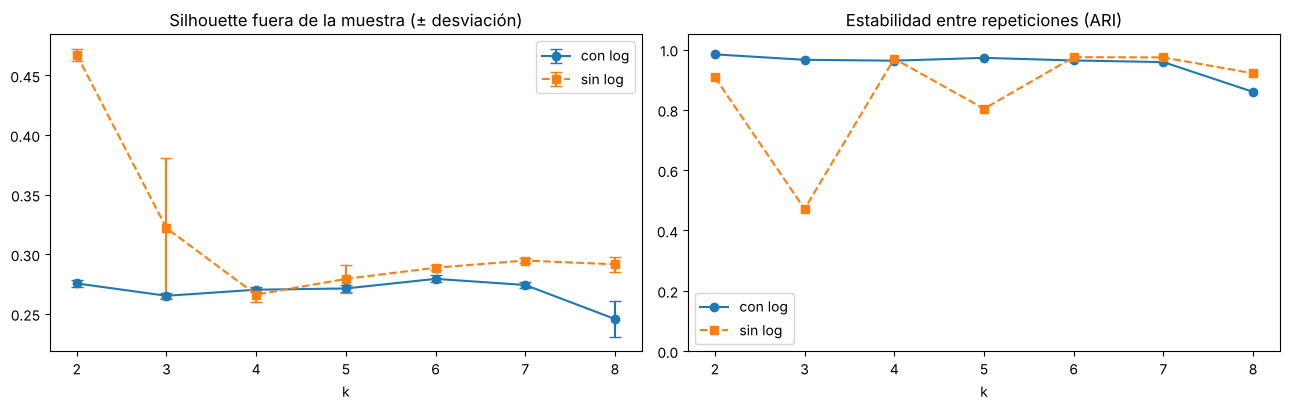

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for nombre, estilo in [("con log", "-o"), ("sin log", "--s")]:
    t = busqueda_k[busqueda_k["preparación"] == nombre]
    ax[0].errorbar(t["k"], t["silhouette_val"], yerr=t["desv_silhouette"], fmt=estilo, capsize=4, label=nombre)
    ax[1].plot(t["k"], t["ARI_estabilidad"], estilo, label=nombre)
ax[0].set(title="Silhouette fuera de la muestra (± desviación)", xlabel="k"); ax[0].legend()
ax[1].set(title="Estabilidad entre repeticiones (ARI)", xlabel="k", ylim=(0, 1.05)); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.**

- **Sin logaritmo**, k = 2 tiene el Silhouette más alto (0,47), pero ya vimos en el Día 4 que solo separa a los «clientes grandes» del resto. Con k = 3 la solución es **inestable** (ARI 0,47: cambia según la muestra) y con k ≥ 3 aparecen grupos diminutos (de 0,2 % a 1,3 %).
- **Con logaritmo**, el Silhouette es casi igual entre k = 2 y 7 (0,265–0,279), casi no varía entre repeticiones (desviación ≈ 0,003) y todas las soluciones son muy estables (ARI ≈ 0,96). Con k = 6 y 7 el grupo más chico baja a 3 %; con k = 8 la estabilidad cae a 0,86.
- La regla para escoger combina las tres cosas: Silhouette alto, ARI alto y grupo más chico ≥ 5 %.

In [27]:
validos = busqueda_k[(busqueda_k["grupo_mas_chico_%"] >= 5) & (busqueda_k["ARI_estabilidad"] >= 0.8)]
print("Combinaciones válidas (grupo más chico ≥ 5 % y ARI ≥ 0,8):")
print(validos.sort_values("silhouette_val", ascending=False).round(3).to_string(index=False))

Combinaciones válidas (grupo más chico ≥ 5 % y ARI ≥ 0,8):
preparación  k  silhouette_val  desv_silhouette  ARI_estabilidad  grupo_mas_chico_%
    sin log  2           0.467            0.005            0.908             13.075
    con log  2           0.276            0.003            0.984             32.663
    con log  5           0.271            0.003            0.972             12.676
    con log  4           0.270            0.002            0.963             14.160
    con log  3           0.265            0.003            0.966             30.268


**Resultado final de la Parte C.** La regla deja arriba «sin log, k = 2» (0,467): es estable y su grupo más chico tiene 13 %, pero sabemos que solo separa a los clientes grandes del resto. **Los números no bastan.** Con logaritmo quedan válidos k = 2 a 5, con Silhouette prácticamente idéntico (0,265–0,276). Entre ellos, el `k = 4` del Día 4 tiene una ventaja que ninguna métrica mide: **sus perfiles se explican** (totaleros, avances, compradores que financian, poco activos). Optimizar un clustering es esto: descartar con números lo que no sirve (inestable, grupos diminutos) y decidir entre lo que queda con interpretación.

# Parte D · Comparación final: tres modelos optimizados en dos datasets

Para cada dataset y cada modelo hacemos lo mismo: `RandomizedSearchCV` con 10 combinaciones y validación cruzada de 5 pliegues sobre 6 000 filas de entrenamiento; escogemos por **F1 en validación cruzada** y, al final, abrimos Test una sola vez para el ganador de cada dataset.

| Modelo | Hiperparámetros que se sortean |
|---|---|
| Árbol | `max_depth`, `min_samples_leaf`, `class_weight` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` |
| KNN (con escalado) | `n_neighbors`, `weights`, `p` |

In [28]:
# BankChurners con la preparación de los Días 3 y 5
ch = pd.read_csv(DATA_DIR / "BankChurners.csv")
y_ch = (ch["Attrition_Flag"] == "Attrited Customer").astype(int)
X_ch = ch.drop(columns=["CLIENTNUM", "Attrition_Flag"] + [c for c in ch.columns if c.startswith("Naive_Bayes")])
CAT_CH = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
NUM_CH = [c for c in X_ch.columns if c not in CAT_CH]
preparar_ch = ColumnTransformer([("num", "passthrough", NUM_CH), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_CH)])
Xch_dev, Xch_test, ych_dev, ych_test = train_test_split(X_ch, y_ch, test_size=0.15, random_state=42, stratify=y_ch)
Xch_tr, _, ych_tr, _ = train_test_split(Xch_dev, ych_dev, train_size=6000, random_state=42, stratify=ych_dev)
Xcr_tr, _, ycr_tr, _ = train_test_split(X_dev, y_dev, train_size=6000, random_state=42, stratify=y_dev)

DATASETS = {"Credit Risk (impago)": (preparar_cr, Xcr_tr, ycr_tr, X_test, y_test),
            "BankChurners (abandono)": (preparar_ch, Xch_tr, ych_tr, Xch_test, ych_test)}
MODELOS = {
    "Árbol": (lambda: DecisionTreeClassifier(random_state=42), False,
              {"m__max_depth": [3, 4, 6, 8, 10, 15, None], "m__min_samples_leaf": randint(1, 60), "m__class_weight": [None, "balanced"]}),
    "Random Forest": (lambda: RandomForestClassifier(random_state=42, n_jobs=-1), False,
              {"m__n_estimators": randint(50, 300), "m__max_depth": [4, 8, 12, 16, None], "m__min_samples_leaf": randint(1, 30),
               "m__max_features": ["sqrt", 0.3, 0.5, 0.8], "m__class_weight": [None, "balanced"]}),
    "KNN": (lambda: KNeighborsClassifier(), True,
            {"m__n_neighbors": randint(3, 60), "m__weights": ["uniform", "distance"], "m__p": [1, 2]})}

filas, mejores = [], {}
inicio = time.time()
for ds, (prep, Xt, yt, Xte, yte) in DATASETS.items():
    for nombre, (crear, escalar, dist) in MODELOS.items():
        pasos = [("preparar", prep)] + ([("escalar", StandardScaler())] if escalar else []) + [("m", crear())]
        busq = RandomizedSearchCV(Pipeline(pasos), dist, n_iter=10, scoring="f1", cv=cv5, return_train_score=True, random_state=42, n_jobs=-1)
        busq.fit(Xt, yt)
        i = busq.best_index_
        filas.append({"dataset": ds, "modelo": nombre, "F1_cv": busq.best_score_, "desv_cv": busq.cv_results_["std_test_score"][i],
                      "F1_train": busq.cv_results_["mean_train_score"][i],
                      "mejores hiperparámetros": {k.replace("m__", ""): (round(v, 2) if isinstance(v, float) else v) for k, v in busq.best_params_.items()}})
        mejores[(ds, nombre)] = busq.best_estimator_
comparacion = pd.DataFrame(filas)
comparacion["brecha"] = comparacion["F1_train"] - comparacion["F1_cv"]
print(f"6 búsquedas × 10 combinaciones × 5 pliegues = 300 entrenamientos en {time.time() - inicio:.0f} s")
comparacion.round(3)

6 búsquedas × 10 combinaciones × 5 pliegues = 300 entrenamientos en 114 s


,dataset,modelo,F1_cv,desv_cv,F1_train,mejores hiperparámetros,brecha
0,Credit Risk (impago),Árbol,0.781,0.012,0.789,"{'class_weight': None, 'max_depth': 6, 'min_sa...",0.008
1,Credit Risk (impago),Random Forest,0.797,0.018,0.814,"{'class_weight': None, 'max_depth': 12, 'max_f...",0.017
2,Credit Risk (impago),KNN,0.653,0.029,1.000,"{'n_neighbors': 4, 'p': 2, 'weights': 'distance'}",0.347
3,BankChurners (abandono),Árbol,0.813,0.020,0.860,"{'class_weight': None, 'max_depth': 6, 'min_sa...",0.047
4,BankChurners (abandono),Random Forest,0.861,0.021,0.996,"{'class_weight': 'balanced', 'max_depth': 16, ...",0.135
5,BankChurners (abandono),KNN,0.451,0.023,1.000,"{'n_neighbors': 4, 'p': 2, 'weights': 'distance'}",0.549


In [29]:
print("F1 en validación cruzada:")
print(comparacion.pivot(index="modelo", columns="dataset", values="F1_cv").round(3))
ganadores = []
for ds, (prep, Xt, yt, Xte, yte) in DATASETS.items():
    t = comparacion[comparacion["dataset"] == ds].sort_values("F1_cv", ascending=False)
    g = t.iloc[0]
    ganadores.append({"dataset": ds, "ganador": g["modelo"], "F1_cv": g["F1_cv"], "desv_cv": g["desv_cv"],
                      "segundo": f"{t.iloc[1]['modelo']} ({t.iloc[1]['F1_cv']:.3f})",
                      "F1 Test": f1_score(yte, mejores[(ds, g['modelo'])].predict(Xte))})
pd.DataFrame(ganadores).set_index("dataset").round(3)

F1 en validación cruzada:
dataset        BankChurners (abandono)  Credit Risk (impago)
modelo                                                      
KNN                              0.451                 0.653
Random Forest                    0.861                 0.797
Árbol                            0.813                 0.781


,ganador,F1_cv,desv_cv,segundo,F1 Test
dataset,,,,,
Credit Risk (impago),Random Forest,0.797,0.018,Árbol (0.781),0.800
BankChurners (abandono),Random Forest,0.861,0.021,Árbol (0.813),0.837


### ¿Qué aprendimos?

- **El Random Forest optimizado gana en los dos datasets** (0,797 en Credit Risk y 0,861 en BankChurners), y su F1 en Test es parecido al de la validación cruzada (0,800 y 0,837): la estimación era confiable.
- **El árbol optimizado** queda cerca en Credit Risk (las reglas de impago son simples: grado del préstamo, proporción cuota/ingreso, tipo de vivienda) y más lejos en BankChurners.
- **KNN**, aun con sus mejores hiperparámetros, queda último en los dos: con todas las columnas sufre la maldición de la dimensionalidad (Día 5). Optimizar hiperparámetros **no** reemplaza a una buena preparación de variables.
- Si dos modelos difieren menos que la desviación entre pliegues, están **empatados**: elige el más simple o el más fácil de explicar.

**Lecciones del día:**

1. **Visualizar muchas dimensiones** exige elegir qué perder: varias vistas de variables originales (matriz, paralelas, mapa de calor) o un mapa reducido (PCA, t-SNE). Ninguna vista sola cuenta toda la historia.
2. **Una sola Validation puede engañar.** La validación cruzada mide varias veces y da un promedio y una desviación.
3. **`GridSearchCV`** prueba todas las combinaciones; **`RandomizedSearchCV`** sortea y explora más con menos tiempo.
4. **Todo va dentro del Pipeline** (imputar, escalar, codificar), para que cada pliegue sea de verdad «datos no vistos».
5. **Test se abre una vez**, al final, para confirmar.
6. **En clustering**, optimizar es buscar un `k` con buen Silhouette fuera de la muestra, **estable** entre repeticiones y con grupos útiles.

# Actividad autónoma

1. En la Parte A, haz el t-SNE con `random_state` 0, 1 y 2 (perplexity 30). ¿Cambia la forma del mapa? ¿Cambian los vecindarios (confiabilidad)?
2. En la Parte B, cambia `n_splits` de 5 a 10. ¿Cambia la mejor combinación? ¿Cuánto más tarda?
3. En la Parte B, agrega `"rf__max_features": ["sqrt", 0.5]` a la rejilla. ¿Cuántos entrenamientos son ahora? ¿Vale la pena?
4. En la Parte D, sube `n_iter` a 30 para KNN en BankChurners y usa solo las 5 variables elegidas en el Día 5. ¿Cuánto mejora?
5. Explica en 150 palabras a un gerente por qué el mejor F1 en Validation no es necesariamente el que conviene escoger.